# Статистические критерии в Python

**Дисциплина:** Введение в анализ больших данных

Темы:
- Shapiro–Wilk (нормальность);
- критерий Фишера (равенство дисперсий);
- Kolmogorov–Smirnov (одна и две выборки);
- t-тест Стьюдента;
- критерий Пирсона (хи-квадрат) для таблиц сопряжённости;
- мозаичные диаграммы / heatmap частот.

Инструменты: **scipy.stats**, **pandas**, **matplotlib**, **seaborn**, **statsmodels**.

Демо-данные: **tips**, **penguins** и синтетические выборки.


In [2]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.mosaicplot import mosaic

plt.rcParams["figure.figsize"] = (10, 6)
sns.set_style("whitegrid")
np.random.seed(42)



# 1 часть. `trees.csv`

---
## 1. Shapiro–Wilk: нормальность

$H_0$: выборка из нормального закона.
При p > 0.05 обычно **не отвергают** $H_0$.
Объём: примерно от 3 до 5000.


In [3]:
trees = pd.read_csv('trees.csv', index_col=0)
trees.columns

Index(['Girth', 'Height', 'Volume'], dtype='str')

In [9]:
for c in trees.columns:
    W, p = stats.shapiro(trees[c])
    print(f"{c:9s}|   W={W:.4f}, p={p:.4g}")

Girth    |   W=0.9412, p=0.08893
Height   |   W=0.9655, p=0.4034
Volume   |   W=0.8876, p=0.003579


Выборка с Volume не распределена по нормальному закону -> $H_0$ Shapiro_wilk отвергается

---
## 2. Критерий Фишера: равенство дисперсий

$H_0$: $\sigma_1^2 = \sigma_2^2$.  - то есть дисперсии выборок равны
Статистика $F = s_1^2 / s_2^2$, p-value — двусторонний по F-распределению.


In [10]:
def f_test(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    F = a.var(ddof=1) / b.var(ddof=1)
    dfn, dfd = len(a) - 1, len(b) - 1
    p = 2 * min(stats.f.cdf(F, dfn, dfd), 1 - stats.f.cdf(F, dfn, dfd))
    return F, p


F, p = f_test(trees["Girth"], trees["Height"])
print(f"  F={F:.4f}, p={p:.4g}")


  F=0.2426, p=0.0002127


Показатель F напрямую отражает различия между дисперсиями (чтобы его интерпретировать, важно посмотреть на отклонение от 1), а p-value зависит от F, но правила те же - это вероятность нулевой гипотезы.

Выборки не равны, отвергаем $H_0$

# 2 часть. randu
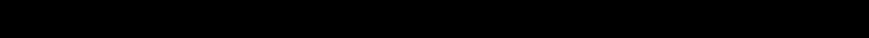


## 3. Kolmogorov–Smirnov

### Две выборки

H0: обе из одного непрерывного распределения.  
`stats.ks_2samp(x, y)`


In [15]:
randu = pd.read_csv('randu.csv', index_col=0)
randu.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 1 to 400
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       400 non-null    float64
 1   y       400 non-null    float64
 2   z       400 non-null    float64
dtypes: float64(3)
memory usage: 9.5 KB


In [16]:
pairs = [('x', 'y'), ('x', 'z'), ('y', 'z')]
for col1, col2 in pairs:
    D, p = stats.ks_2samp(randu[col1], randu[col2])
    print(f"{col1} vs {col2}: D={D:.4f}, p={p:.4g}")


x vs y: D=0.0850, p=0.1111
x vs z: D=0.0875, p=0.09352
y vs z: D=0.0475, p=0.7583


### Вывод. Kolmogorov–Smirnov
Нулевая гипотеза для всех пар подтверждается.

D-статистика - этот показатель отражает максимальное расстояние между функциями распределения двух выборок, которые мы сравнивали. По сути вертикальный разрыв на графике гистограммы

### Одна выборка: согласие с законом

`stats.kstest(x, "norm", args=(mu, sigma))`  
`stats.kstest(x, "uniform", args=(loc, scale))`


In [22]:
mu, sigma = randu['x'].mean(), randu['x'].std(ddof=1)
D, p = stats.kstest(randu['x'], stats.norm.cdf, args=(mu, sigma))
print(f"randu['x']: D={D:.4f}, p={p:.4g}")

D, p = stats.kstest(randu['y'], stats.uniform.cdf, args=(0, 1))
print(f"randu['y']: D={D:.4f}, p={p:.4g}")


randu['x']: D=0.0733, p=0.02569
randu['y']: D=0.0357, p=0.6739


### Вывод

$H_0$: данные статистически похожи

Проще всего смотреть на это так: `показатель D` - это разница между максимальными значениями двух выборок условно, тогда `p-value` - это вероятность того, что D не случайно

Значит по выводу из кода
x - не является выборкой, распределённой по нормальному закону
y - является равномерно распределённой выборкой, причём y ещё и очень сильно похож на идеальную математическую модель равномерной выборки


# 3 часть. ldeaths

In [31]:
ldeaths = pd.read_csv('ldeaths.csv', index_col=0)
ldeaths.info()

ldeaths['Year'] = ldeaths['time'].astype(int)

<class 'pandas.DataFrame'>
RangeIndex: 72 entries, 1 to 72
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   time    72 non-null     float64
 1   value   72 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 1.3 KB


---
## 4. t-тест Стьюдента: равенство средних

H0: $\mu_1 = \mu_2$.  
`stats.ttest_ind(a, b, equal_var=False)` — версия Уэлча (не требует равенства дисперсий).


In [32]:
a = ldeaths[ldeaths['Year'] == 1974]['value']
b = ldeaths[ldeaths['Year'] == 1979]['value']

t, p = stats.ttest_ind(a, b, equal_var=False)
print(f"Средние value: 1974 vs 1979")
print(f"  mean 1974 = {a.mean():.2f}, 1979 = {b.mean():.2f}")
print(f"  t={t:.4f}, p={p:.4g}")


Средние value: 1974 vs 1979
  mean 1974 = 2178.33, 1979 = 1911.50
  t=1.2221, p=0.2349


In [33]:
F_val, p_f = f_test(a, b)
print(f"  F = {F_val:.4f}, p = {p_f:.4g}")

  F = 0.7470, p = 0.6369


### Вывод

$H_0$: средние значения двух генеральных совокупностей равны

p = 0.2349 (p > 0.1 для медицинских данных), мы не отвергаем нулевую гипотезу

t-статистика показывает, что есть большой шум, из-за чего мы не можем быть до конца уверены, что эти значения реальны, а не шум, из-за сезонности например

Дисперсии двух выборок равны по F-стату



# 4 часть. HairEyeColor

In [35]:
HairEyeColor = pd.read_csv('HairEyeColor.csv', index_col=0)
HairEyeColor.head()

,Hair,Eye,Sex,Freq
rownames,,,,
1,Black,Brown,Male,32
2,Brown,Brown,Male,53
3,Red,Brown,Male,10
4,Blond,Brown,Male,3
5,Black,Blue,Male,11


In [38]:
print(f"Уникальные значения Hair: {HairEyeColor['Hair'].unique()}")
print(f"Уникальные значения Eye: {HairEyeColor['Eye'].unique()}")
print(f"Уникальные значения Sex: {HairEyeColor['Sex'].unique()}")

Уникальные значения Hair: <StringArray>
['Black', 'Brown', 'Red', 'Blond']
Length: 4, dtype: str
Уникальные значения Eye: <StringArray>
['Brown', 'Blue', 'Hazel', 'Green']
Length: 4, dtype: str
Уникальные значения Sex: <StringArray>
['Male', 'Female']
Length: 2, dtype: str


---
## 5. Хи-квадрат Пирсона: независимость признаков

$H_0$: признаки независимы.
`stats.chi2_contingency(table)`


In [46]:
male_data = HairEyeColor[HairEyeColor['Sex'] == 'Male']
ct_male = pd.pivot_table(male_data, values='Freq', index='Hair', columns='Eye', fill_value=0)

female_data = HairEyeColor[HairEyeColor['Sex'] == 'Female']
ct_female = pd.pivot_table(female_data, values='Freq', index='Hair', columns='Eye', fill_value=0)


chi2_m, p_m, dof_m, _ = stats.chi2_contingency(ct_male)
chi2_f, p_f, dof_f, _ = stats.chi2_contingency(ct_female)

print("===== Male stats =====")
print(ct_male)
print(f"\nchi^2 = {chi2_m:.3f}, df={dof_m}, p={p_m:.4g}")


print("\n===== Female stats =====")
print(ct_female)
print(f"\nchi^2 = {chi2_f:.3f}, df={dof_f}, p={p_f:.4g}")


===== Male stats =====
Eye    Blue  Brown  Green  Hazel
Hair                            
Black  11.0   32.0    3.0   10.0
Blond  30.0    3.0    8.0    5.0
Brown  50.0   53.0   15.0   25.0
Red    10.0   10.0    7.0    7.0

chi^2 = 41.280, df=9, p=4.447e-06

===== Female stats =====
Eye    Blue  Brown  Green  Hazel
Hair                            
Black   9.0   36.0    2.0    5.0
Blond  64.0    4.0    8.0    5.0
Brown  34.0   66.0   14.0   29.0
Red     7.0   16.0    7.0    7.0

chi^2 = 106.664, df=9, p=7.014e-19


### Вывод

$H_0$: Признаки независимы

$df$ - Степени свободы = (количество строк - 1) * (количество столбцов - 1)

$χ^2$ - хи-квадрат сумма квадратов разницы фактических и гипотетических идеальных данных. (Чем-то похоже на Kolmogorov–Smirnov согласие с законом)


> p-value везде меньше 0.05, что отвергает нулевую гипотезу.
>
> $χ^2$ довольно большой, особенно у женщин, это определяет силу связи.


### Мозаика и heatmap частот


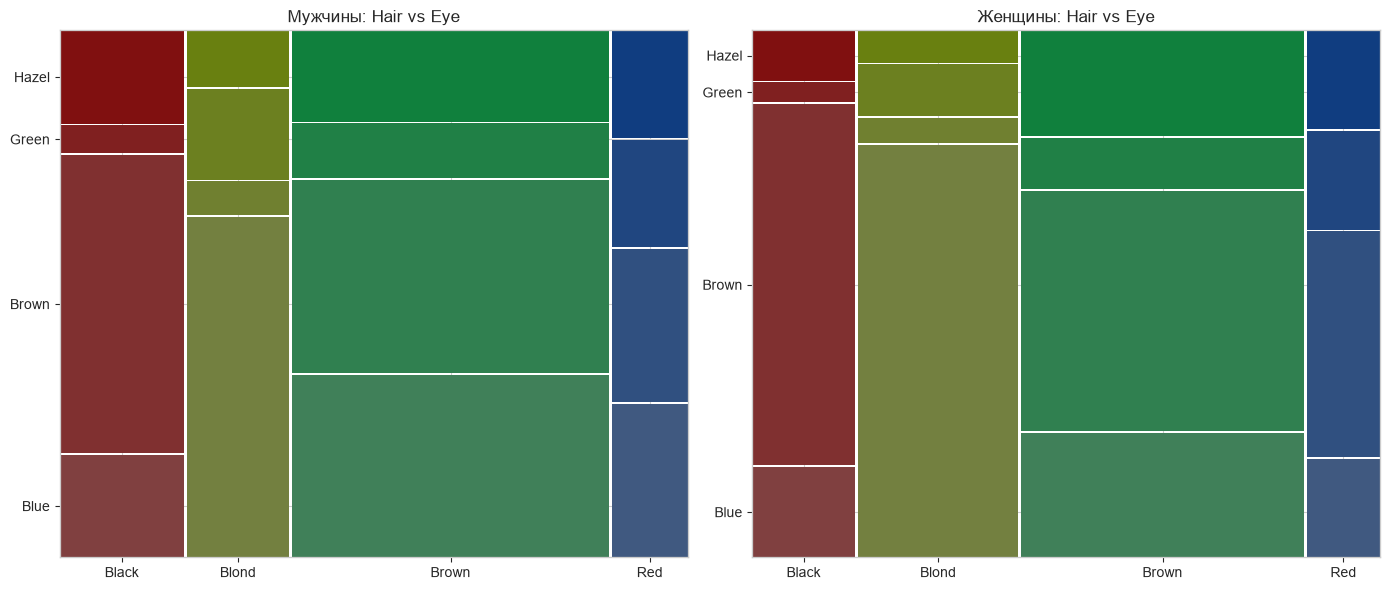

In [47]:
def prepare_mosaic_data(table):
    return {(str(r), str(c)): table.loc[r, c] for r in table.index for c in table.columns}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

mosaic(prepare_mosaic_data(ct_male), ax=axes[0], title='Мужчины: Hair vs Eye', labelizer=lambda k: '')
mosaic(prepare_mosaic_data(ct_female), ax=axes[1], title='Женщины: Hair vs Eye', labelizer=lambda k: '')

plt.tight_layout()
plt.show()

### Вывод по графикам

Судя по картинке, если бы у нас были ровные горизонтальные линии, то можно было бы сказать, что у нас независимые признаки, а так - статистическая зависимость визуально

---
## 6. Краткая сводка по penguins (дополнительно)

Несколько тестов подряд на одном датасете.


In [ ]:
peng = sns.load_dataset("penguins").dropna()
print("Shapiro body_mass_g:")
W, p = stats.shapiro(peng["body_mass_g"])
print(f"  W={W:.4f}, p={p:.4g}")

adel = peng.loc[peng["species"] == "Adelie", "body_mass_g"]
gent = peng.loc[peng["species"] == "Gentoo", "body_mass_g"]
t, p = stats.ttest_ind(adel, gent, equal_var=False)
print(f"\nt-тест массы Adelie vs Gentoo: t={t:.3f}, p={p:.4g}")

ct_p = pd.crosstab(peng["species"], peng["island"])
chi2, p, dof, _ = stats.chi2_contingency(ct_p)
print(f"\nХи-квадрат species × island: chi2={chi2:.2f}, p={p:.4g}")
print(ct_p)


---
## Шпаргалка по методам (Python)

| Задача | Код |
|--------|-----|
| Shapiro–Wilk | `stats.shapiro(x)` → (W, p) |
| F-тест дисперсий | `F = s1/s2`; p через `stats.f.cdf` |
| KS две выборки | `stats.ks_2samp(x, y)` |
| KS vs нормальное | `stats.kstest(x, "norm", args=(mu, sigma))` |
| KS vs равномерное | `stats.kstest(x, "uniform", args=(a, b-a))` |
| t-тест средних | `stats.ttest_ind(a, b, equal_var=False)` |
| Хи-квадрат | `stats.chi2_contingency(table)` |
| Таблица частот | `pd.crosstab(A, B)` |
| Мозаика | `statsmodels.graphics.mosaicplot.mosaic` |

---
## Что сделать после лекции

1. Откройте лабораторное задание и выполните его **самостоятельно** на указанных таблицах.  
2. При интерпретации: p > 0.05 → H0 обычно **не отвергают** (на уровне 0.05).

Удачи!
